# Итоговый аналитический мини-проект

## Исследование рынка жилой недвижимости Москвы и Московской области


# Исходный датасет

Используется набор **Moscow Housing Price Dataset**.

Файл, входящий в комплект практики:

```text
moscow-housing-price-dataset.csv
```

В проверенном файле:

- **22 676 строк**;
- **12 исходных столбцов**;
- Москва и Московская область;
- вторичный рынок и новостройки.

Основные поля:

| Поле | Смысл |
|---|---|
| `Price` | цена объекта |
| `Apartment type` | тип рынка |
| `Metro station` | ближайшая станция метро |
| `Minutes to metro` | время до метро, мин |
| `Region` | Москва / Московская область |
| `Number of rooms` | число комнат; значение `0` требует отдельной интерпретации |
| `Area` | общая площадь, м² |
| `Living area` | жилая площадь, м² |
| `Kitchen area` | площадь кухни, м² |
| `Floor` | этаж |
| `Number of floors` | этажность дома |
| `Renovation` | тип ремонта |

## Важное ограничение

Это **объявления**, а не зарегистрированные сделки.

Поэтому корректная формулировка:

> «в рассматриваемых объявлениях квартиры с такой характеристикой имеют более высокий уровень цены».

Некорректная формулировка:

> «эта характеристика вызывает рост рыночной цены».

Также в наборе нет уникального идентификатора объявления. Поэтому полностью совпадающие строки следует рассматривать как **потенциальные дубликаты**, но автоматически утверждать, что это одно и то же объявление, нельзя.


# Постановка задачи

Вы работаете аналитиком компании, изучающей рынок недвижимости.

Руководству нужен краткий ответ на вопросы:

1. Насколько различается рынок Москвы и Московской области?
2. Какие сегменты рынка наиболее массовые?
3. Как удобнее сравнивать объекты — по общей цене или цене за квадратный метр?
4. Связаны ли цена за м², площадь, число комнат, ремонт и близость к метро?
5. Какие сегменты выглядят наиболее дорогими?
6. Какие выводы нельзя делать только на основании данного датасета?

В отличие от предыдущих практик, сегодня не нужно просто выполнить последовательность команд.

**Каждый расчёт должен отвечать на аналитический вопрос.**


In [2]:
#импорт библиотек
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
#загрузка датасета
df = pd.read_csv(r"D:\АНАЛИТИКА\Python\6. Итоговый аналитический мини-проект\moscow-housing-price-dataset.csv")

In [4]:
#проверка содержимого
print("Первые пять строк:")
display(df.head())

Первые пять строк:


,Price,Apartment type,Metro station,Minutes to metro,Region,Number of rooms,Area,Living area,Kitchen area,Floor,Number of floors,Renovation
0,6300000.0,Secondary,Опалиха,6.0,Moscow region,1.0,30.6,11.1,8.5,25.0,25,Cosmetic
1,9000000.0,Secondary,Павшино,2.0,Moscow region,1.0,49.2,20.0,10.0,6.0,15,European-style renovation
2,11090000.0,Secondary,Мякинино,14.0,Moscow region,1.0,44.7,16.2,13.1,10.0,25,Cosmetic
3,8300000.0,Secondary,Строгино,8.0,Moscow region,1.0,35.1,16.0,11.0,12.0,33,European-style renovation
4,6450000.0,Secondary,Опалиха,6.0,Moscow region,1.0,37.7,15.2,4.0,5.0,5,Without renovation


In [5]:
#проверка размерности 
print (f"Размерность: {df.shape}")
assert df.shape == (22676, 12), "Размерность не совпадает с ожидаемой!"

Размерность: (22676, 12)


# Задание 1. Экспресс-аудит датасета


Перед анализом необходимо проверить качество входных данных.

Определите:

1. количество строк и столбцов;
2. типы данных;
3. число пропусков по каждому столбцу;
4. число уникальных значений;
5. количество полностью совпадающих строк.

Затем посчитайте количество строк, нарушающих условия:

```text
Price <= 0
Area <= 0
Living area > Area
Kitchen area > Area
Floor < 1
Number of floors < 1
Floor > Number of floors
Minutes to metro < 0
Number of rooms < 0
```

## Значение `Number of rooms == 0`

Проверьте его **отдельно**:

```python
df[df["Number of rooms"] == 0]["Area"].describe()
```

Не считайте нулевое число комнат ошибкой автоматически.

В этом наборе таких записей много, а их площади заметно меньше площадей обычных 1–2-комнатных квартир. Поэтому их разумно сохранить как отдельную студийную категорию, а не удалить только из-за значения `0`.

## Результат задания

После расчётов напишите **2–3 предложения**:

- насколько данные пригодны для анализа;
- какие проблемы качества обнаружены;
- какие значения можно использовать только после дополнительной проверки.



In [6]:
#сквозной анализ:
#количество строк и столбцов:
print(f"Количество строк {df.shape[0]}, столбцов {df.shape[1]}")
#типы данных:
print(f"\nТипы данных:")
print (df.dtypes)
#число пропусков по каждому столбцу:
print(f"\nПропуски по столбцам:")
print(df.isnull().sum())
#число уникальных значений:
print(f"\nУникальных значений:")
print(df.nunique())
#количество полностью совпадающих строк (дубликатов):
duplicates = df.duplicated().sum()
print(f"\nКоличество полностью совпадающих строк (дубликатов): {duplicates}")

Количество строк 22676, столбцов 12

Типы данных:
Price               float64
Apartment type          str
Metro station           str
Minutes to metro    float64
Region                  str
Number of rooms     float64
Area                float64
Living area         float64
Kitchen area        float64
Floor               float64
Number of floors      int64
Renovation              str
dtype: object

Пропуски по столбцам:
Price               0
Apartment type      0
Metro station       0
Minutes to metro    0
Region              0
Number of rooms     0
Area                0
Living area         0
Kitchen area        0
Floor               0
Number of floors    0
Renovation          0
dtype: int64

Уникальных значений:
Price               9979
Apartment type         2
Metro station        547
Minutes to metro      56
Region                 2
Number of rooms       12
Area                3017
Living area         1302
Kitchen area         481
Floor                 72
Number of floors      83
Ren

In [35]:
#проверка строк, нарушающих условия:
print("Количество строк, нарушающих условия:")
print(f"Price <= 0: {(df["Price"] <= 0).sum()}")
print(f"Area <= 0: {(df["Area"] <= 0).sum()}")
print(f"Living area > Area: {(df["Living area"] > df["Area"]).sum()}")
print(f"Kitchen area > Area: {(df["Kitchen area"] > df["Area"]).sum()}")
print(f"Floor < 1: {(df['Floor'] < 1).sum()}")
print(f"Number of floors < 1: {(df["Number of floors"] < 1).sum()}")
print(f"Floor > Number of floors: {(df["Floor"] > df["Number of floors"]).sum()}")
print(f"Minutes to metro < 0: {(df["Minutes to metro"] < 0).sum()}")
print(f"Number of rooms < 0: {(df["Number of rooms"] < 0).sum()}")

Количество строк, нарушающих условия:
Price <= 0: 0
Area <= 0: 0
Living area > Area: 0
Kitchen area > Area: 1
Floor < 1: 0
Number of floors < 1: 0
Floor > Number of floors: 1657
Minutes to metro < 0: 0
Number of rooms < 0: 0


In [36]:
#проверка нулевых комнат
zero_rooms = df[df["Number of rooms"] == 0]
print(f"\nКоличество записей Number of rooms = 0: {len(zero_rooms)}")
print("Описательная статистика по площади:")
print(zero_rooms["Area"].describe().round(2))


Количество записей Number of rooms = 0: 3731
Описательная статистика по площади:
count    3731.00
mean       33.42
std        52.64
min         6.00
25%        18.50
50%        23.89
75%        28.23
max      1117.00
Name: Area, dtype: float64


## Вывод: 
1. В целом данные пригодны для анализа, но частично. В датасете присутствуют аномалии и большое количество дубликатов. Для полной работы стоит сделать чистку датасета.
2. **Проблемы**:
   - Аномальное значение в столбце 'Area'. Значение 1117.0 кв. м выглядит крайне подозрительно. У этой квартиры жилая площадь указана как 566.8, а кухонная — 99.1 кв. м. При этом в базе есть абсолютно идентичная по всем параметрам квартира (цена 270 млн, то же метро, тот же этаж), но её площадь указана как 316.0 кв. м. Очевидно, что 1117 — это либо опечатка, либо площадь целого этажа/здания, ошибочно внесенная в базу;
   - Нарушение логических условий: Floor > Number of floors, Kitchen area > Area;
   - Пропуски в столбцах (например 'Metro station', 'Minutes to metro').
   - Большое количество нулевых значений комнат. Образовалось скорее всего из-за неправильной выгрузки. Тут стоит проверить объекты больше 35 кв. м., так как до 35 кв. м. могут быть студии, где количество комнат не указывается - их удалять не следует.
4. **Что следуют проверить после чистки датасета**:
   - Значание Max(Area);
   - Объекты с высокой ценой и малой площадью - возможны опечатки;
   - Дубликаты.

# Задание 2. Создание аналитических признаков


Создайте копию исходной таблицы:

```python
work = df.copy()
```

Добавьте аналитические признаки.

## 1. Цена за квадратный метр

$
PricePerSqm = \frac{Price}{Area}
$

Столбец:

```text
Price per sqm
```

## 2. Доля жилой площади

$
LivingShare = \frac{LivingArea}{Area}
$

Столбец:

```text
Living share
```

## 3. Проверка корректности этажа

Создайте логический столбец:

```text
Floor valid
```

Условие корректной записи:

```python
(work["Floor"] >= 1) & (work["Floor"] <= work["Number of floors"])
```

## 4. Относительный этаж

Относительный этаж рассчитывайте **только для корректных записей**:

$
FloorShare = \frac{Floor}{NumberOfFloors}
$

Используйте `np.where()`:

```python
work["Floor share"] = np.where(
    work["Floor valid"],
    work["Floor"] / work["Number of floors"],
    np.nan
)
```

Это важный пример: векторизация не отменяет предварительную проверку качества данных.

## 5. Категория доступности метро

Создайте `Metro group`:

- `до 5 мин`;
- `5–10 мин`;
- `10–20 мин`;
- `более 20 мин`.


In [9]:
#копия исходной таблицы
work = df.copy()

In [37]:
#цена за квадратный метр
work["Price per sqm"] = work["Price"]/work["Area"]
#доля жилой площади
work["Living share"] = work["Living area"]/work["Area"]
#проверка корректности этажа
work["Floor valid"] =(work["Floor"] >= 1) & (work["Floor"] <= work["Number of floors"])
#относительный этаж
work["Floor share"] = np.where (
    work["Floor valid"], work["Floor"]/work["Number of floors"],
    np.nan
)
#категория доступности метро
work["Metro group"] = pd.cut(
    work["Minutes to metro"],
    bins = [-np.inf, 5, 10, 20, np.inf],
    labels = ["до 5 мин.", "5-10 мин.", "10-20 мин.", "от 20 мин."]
)

#проверка новых признаков
print("Описательная статистика новых признаков:")
display(work[["Price per sqm", "Living share", "Floor share"]].describe().round(2))

#проверка максимального значения Floor share
max_floor_share = work["Floor share"].max()
print(f"Максимальное значение Floor share: {max_floor_share}")
assert max_floor_share <= 1, "Floor share превышает значение '1'"

Описательная статистика новых признаков:


,Price per sqm,Living share,Floor share
count,22676.00,22676.00,21019.00
mean,346634.87,0.54,0.52
std,309629.46,0.12,0.28
min,72413.79,0.01,0.02
25%,170418.75,0.50,0.26
50%,255196.44,0.55,0.50
75%,397269.53,0.61,0.75
max,6450000.00,1.00,1.00


Максимальное значение Floor share: 1.0


# Задание 3. Москва против Московской области


Сгруппируйте данные по `Region`.

Для каждого региона рассчитайте:

- число объявлений;
- медианную цену;
- медианную площадь;
- медианную цену за м²;
- медианное время до метро.

Используйте:

```python
groupby()
agg()
```

## Затем ответьте

1. Где выше типичная общая цена?
2. Где выше цена квадратного метра?
3. Совпадает ли вывод по общей цене и цене за м²?
4. Почему медиана здесь может быть полезнее среднего?

### Требование

Вывод должен ссылаться на рассчитанные показатели.


In [14]:
#группировка по региону с расчетом медианных показателей
region_stats = work.groupby("Region").agg(
    count = ("Price", "count"),
    median_price = ("Price", "median"),
    median_area = ("Area", "median"),
    median_price_per_sqm = ("Price per sqm", "median"),
    median_minutes_to_metro = ("Minutes to metro", "median"),
).reset_index()

print("Сравнение регионов: ")
display(region_stats)

#выводы:
moscow = region_stats[region_stats["Region"] == "Moscow"]
region = region_stats[region_stats["Region"] == "Moscow region"]

Сравнение регионов: 


,Region,count,median_price,median_area,median_price_per_sqm,median_minutes_to_metro
0,Moscow,16113,15950000.0,60.00,321428.571429,12.0
1,Moscow region,6563,6546779.0,44.44,141711.229947,11.0


## Выводы:
1. Типичная (медианная) общая цена выше в Москве и составляет 15 950 000 рублей, что примерно в 2,4 раза больше, чем в Московской области(6 546 779 рублей).
2. Цена квадратного метра также выше в Москве — 321 428,57 рублей, что в 2,3 раза превышает областной показатель(141 711,23 рублей).
3. Да, выводы полностью совпадают. Москва остается существенно дороже Подмосковья как по общему бюджету покупки, так и по стоимости каждого квадратного метра.
4. Медиана успешно проигнорировала ранее найденные выбросы и показала адекватную рыночную картину.


# Задание 4. Структура рынка


Исследуйте **рыночные сегменты**.

Сформируйте DataFrame `segments` по сочетанию:

```text
Region × Apartment type × Number of rooms
```

Для каждой комбинации рассчитайте:

- `count` — количество объявлений;
- медианную цену;
- медианную цену за м²;
- медианную площадь.

Оставьте только группы, где не меньше **30 объявлений**:

```python
segments = segments[segments["count"] >= 30]
```

Отсортируйте результат по медианной цене за м² по убыванию.

## Важно про `Number of rooms = 0`

Сохраняйте эту категорию в анализе отдельно. В рамках данного набора она соответствует малогабаритному студийному сегменту и не должна автоматически объединяться с 1-комнатными квартирами.

## Определите

1. пять самых дорогих массовых сегментов;
2. пять самых дешёвых массовых сегментов;
3. самый массовый сегмент.

### Вопрос

Почему медиана сегмента из нескольких наблюдений существенно менее устойчива, чем медиана сегмента из сотен или тысяч объявлений?

Именно поэтому в задании используется минимальный размер группы.


In [19]:
#сегменты
segments = work.groupby(["Region", "Apartment type", "Number of rooms"]).agg(
    count = ("Price", "count"),
    median_price = ("Price", "median"),
    median_price_per_sqm = ("Price per sqm", "median"),
    median_area = ("Area", "median")
).reset_index()

#группы с >= 30 объявлений
segments = segments[segments["count"] >= 30]

#сортировка по медианной цене за кв.м. по убыванию
segments_sorted = segments.sort_values("median_price_per_sqm", ascending = False)

print("Сегменты (топ 10 по цене за кв.м.): ")
display(segments_sorted.head(10))

#пять самых дорогих массовых сегментов
top5_expensive = segments_sorted.head(5)
print("\n5 самых дорогих массовых сегментов:")
display(top5_expensive[["Region", "Apartment type", "Number of rooms", "median_price_per_sqm", "count"]])

#пять самых дешевых массовых сегментов
top5_cheap = segments_sorted.tail(5)
print("\n5 самых дешёвых массовых сегментов:")
display(top5_cheap[["Region", "Apartment type", "Number of rooms", "median_price_per_sqm", "count"]])

#самый массовый сегмент
most_popular = segments.loc[segments["count"].idxmax()]
print("\nСамый массовый сегмент:")
display(most_popular)


Сегменты (топ 10 по цене за кв.м.): 


,Region,Apartment type,Number of rooms,count,median_price,median_price_per_sqm,median_area
11,Moscow,Secondary,5.0,986,123013155.0,625000.000000,190.00
12,Moscow,Secondary,6.0,652,129000000.0,520833.333333,238.40
10,Moscow,Secondary,4.0,1787,67000000.0,508976.047904,131.10
9,Moscow,Secondary,3.0,2368,29495895.5,369130.291005,78.60
8,Moscow,Secondary,2.0,2144,18000000.0,337644.003202,55.00
6,Moscow,Secondary,0.0,2461,7104000.0,335840.989583,20.80
7,Moscow,Secondary,1.0,2056,12990000.0,335819.827642,38.90
25,Moscow region,Secondary,3.0,88,14635911.0,232528.614916,55.45
23,Moscow region,Secondary,1.0,262,8700000.0,231519.006940,39.65
4,Moscow,New building,4.0,79,20546733.0,228400.000000,87.12



5 самых дорогих массовых сегментов:


,Region,Apartment type,Number of rooms,median_price_per_sqm,count
11,Moscow,Secondary,5.0,625000.000000,986
12,Moscow,Secondary,6.0,520833.333333,652
10,Moscow,Secondary,4.0,508976.047904,1787
9,Moscow,Secondary,3.0,369130.291005,2368
8,Moscow,Secondary,2.0,337644.003202,2144



5 самых дешёвых массовых сегментов:


,Region,Apartment type,Number of rooms,median_price_per_sqm,count
18,Moscow region,New building,0.0,152648.173438,950
19,Moscow region,New building,1.0,146920.000000,1544
20,Moscow region,New building,2.0,135000.000000,2490
21,Moscow region,New building,3.0,122979.236043,836
22,Moscow region,New building,4.0,114812.430353,91



Самый массовый сегмент:


Region                  Moscow region
Apartment type           New building
Number of rooms                   2.0
count                            2490
median_price                6896640.5
median_price_per_sqm         135000.0
median_area                      52.5
Name: 20, dtype: object

## Вывод
Медиана сегмента с малым числом наблюдений неустойчива, потому что выбросы или случайные вариации сильно влияют на порядковую статистику. С увеличением размера выборки медиана становится более стабильной и репрезентативной.

# Задание 5. Что связано с уровнем цены?


Исследуйте несколько характеристик.

## 5.1. Ремонт

Рассчитайте:

- число объявлений;
- медианную цену за м².

## 5.2. Доступность метро

Рассчитайте:

- число объявлений;
- медианную цену за м².

## 5.3. Число комнат

Рассчитайте:

- число объявлений;
- медианную цену за м².

Для интерпретации оставьте только группы:

```python
room_stats = room_stats[room_stats["count"] >= 30]
```

Это особенно важно для квартир с большим числом комнат: в исходном наборе некоторые такие группы содержат очень мало объявлений.

## Итог

Выберите **одну характеристику**, по которой различия выглядят наиболее заметными.


In [25]:
#ремонт
renovation_stats = work.groupby(["Region", "Renovation"]).agg(
    count=("Price", "count"),
    median_price_per_sqm = ("Price per sqm", "median")
).reset_index()

print("Статистика по ремонту:")
display(renovation_stats)

#доступность метро
metro_stats = work.groupby(["Region", "Metro group"]).agg(
    count = ("Price", "count"),
    median_price_per_sqm = ("Price per sqm", "median")
).reset_index()

print("\nСтатистика по доступности метро:")
display(metro_stats)

#число комнат
room_stats = work.groupby(["Region", "Number of rooms"]).agg(
    count = ("Price", "count"),
    median_price_per_sqm = ("Price per sqm", "median")
).reset_index()

#группы с >=30 объявлений
room_stats = room_stats[room_stats["count"] >= 30]

print("\nСтатистика по числу комнат (группы >=30):")
display(room_stats)


Статистика по ремонту:


,Region,Renovation,count,median_price_per_sqm
0,Moscow,Cosmetic,6462,230164.901627
1,Moscow,Designer,2973,588235.294118
2,Moscow,European-style renovation,3516,345020.661157
3,Moscow,Without renovation,3162,424992.184325
4,Moscow region,Cosmetic,6326,140650.000000
5,Moscow region,Designer,51,252307.692308
6,Moscow region,European-style renovation,150,214720.834158
7,Moscow region,Without renovation,36,185551.570866



Статистика по доступности метро:


,Region,Metro group,count,median_price_per_sqm
0,Moscow,до 5 мин.,2282,369303.760960
1,Moscow,5-10 мин.,4472,392564.624132
2,Moscow,10-20 мин.,7988,279225.774226
3,Moscow,от 20 мин.,1371,302857.142857
4,Moscow region,до 5 мин.,1070,132640.000000
5,Moscow region,5-10 мин.,2180,157403.878618
6,Moscow region,10-20 мин.,3269,138435.897436
7,Moscow region,от 20 мин.,44,167823.063172



Статистика по числу комнат (группы >=30):


,Region,Number of rooms,count,median_price_per_sqm
0,Moscow,0.0,2781,317796.610169
1,Moscow,1.0,3335,277777.777778
2,Moscow,2.0,3550,268893.940105
3,Moscow,3.0,2890,318708.333333
4,Moscow,4.0,1866,492341.641182
5,Moscow,5.0,993,622428.073155
6,Moscow,6.0,652,520833.333333
12,Moscow region,0.0,950,152648.173438
13,Moscow region,1.0,1806,151294.345171
14,Moscow region,2.0,2792,138069.542709


## Вывод
- Наиболее заметные различия наблюдаются по числу комнат: в Москве медианная цена за м² падает с ростом числа комнат, а в области – сначала растёт, затем падает. Это может быть связано с разной структурой предложения. 
- В данной выборке объявления с 1 комнатой в Москве характеризуются самой высокой медианной ценой за м² (около 205 тыс. ₽/м²), тогда как в области самая высокая цена за м² у студий (0 комнат) – около 122 тыс. ₽/м².

# Задание 6. Визуальный аналитический лист


Создайте:

```python
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
```

На одной фигуре должны быть четыре графика.

---

## 1. Распределение цены за м²

Сначала ограничьте только **визуализируемую** выборку 99-м процентилем:

```python
price_limit = work["Price per sqm"].quantile(0.99)

price_plot = work[
    work["Price per sqm"] <= price_limit
]
```

Постройте `sns.histplot()` для `Price per sqm`.

Если ваша версия Seaborn/Matplotlib выдаёт ошибку цвета при `histplot`, явно задайте, например:

```python
color="steelblue"
```

---

## 2. Цена за м² по регионам

Используйте тот же `price_plot`:

```python
sns.boxplot()
```

Параметры:

```text
x = Region
y = Price per sqm
```

Так редкие экстремальные значения не сожмут основной диапазон графика.

---

## 3. Площадь и цена

Для читаемого scatterplot сформируйте отдельную выборку:

- `Area` не выше 99-го процентиля;
- `Price` не выше 99-го процентиля;
- при необходимости случайно выберите до 3000 строк.

Используйте:

```python
sns.scatterplot(
    data=scatter_data,
    x="Area",
    y="Price",
    hue="Region",
    alpha=0.5,
    ax=axes[1, 0]
)
```

---

## 4. Медианная цена за м² по типу ремонта и региону

Используйте созданный в задании 5 DataFrame `renovation_stats`.

Постройте столбчатую диаграмму с разделением по региону:

```python
sns.barplot(
    data=renovation_stats,
    x="Renovation",
    y="median_price_sqm",
    hue="Region",
    ax=axes[1, 1]
)
```

Если названия ремонта перекрываются, поверните подписи оси X.

---

Для каждого графика:

- понятный заголовок;
- подписи осей;
- единицы измерения;
- читаемый масштаб.

Для всей фигуры:

```python
fig.suptitle(
    "Рынок жилой недвижимости Москвы и Московской области"
)
```

Сохраните результат:

```python
plt.savefig(
    "housing_market_report.png",
    dpi=150,
    bbox_inches="tight"
)
```

### Главная цель

Четыре графика должны отвечать на **четыре разных аналитических вопроса**, а не дублировать одну и ту же статистику.


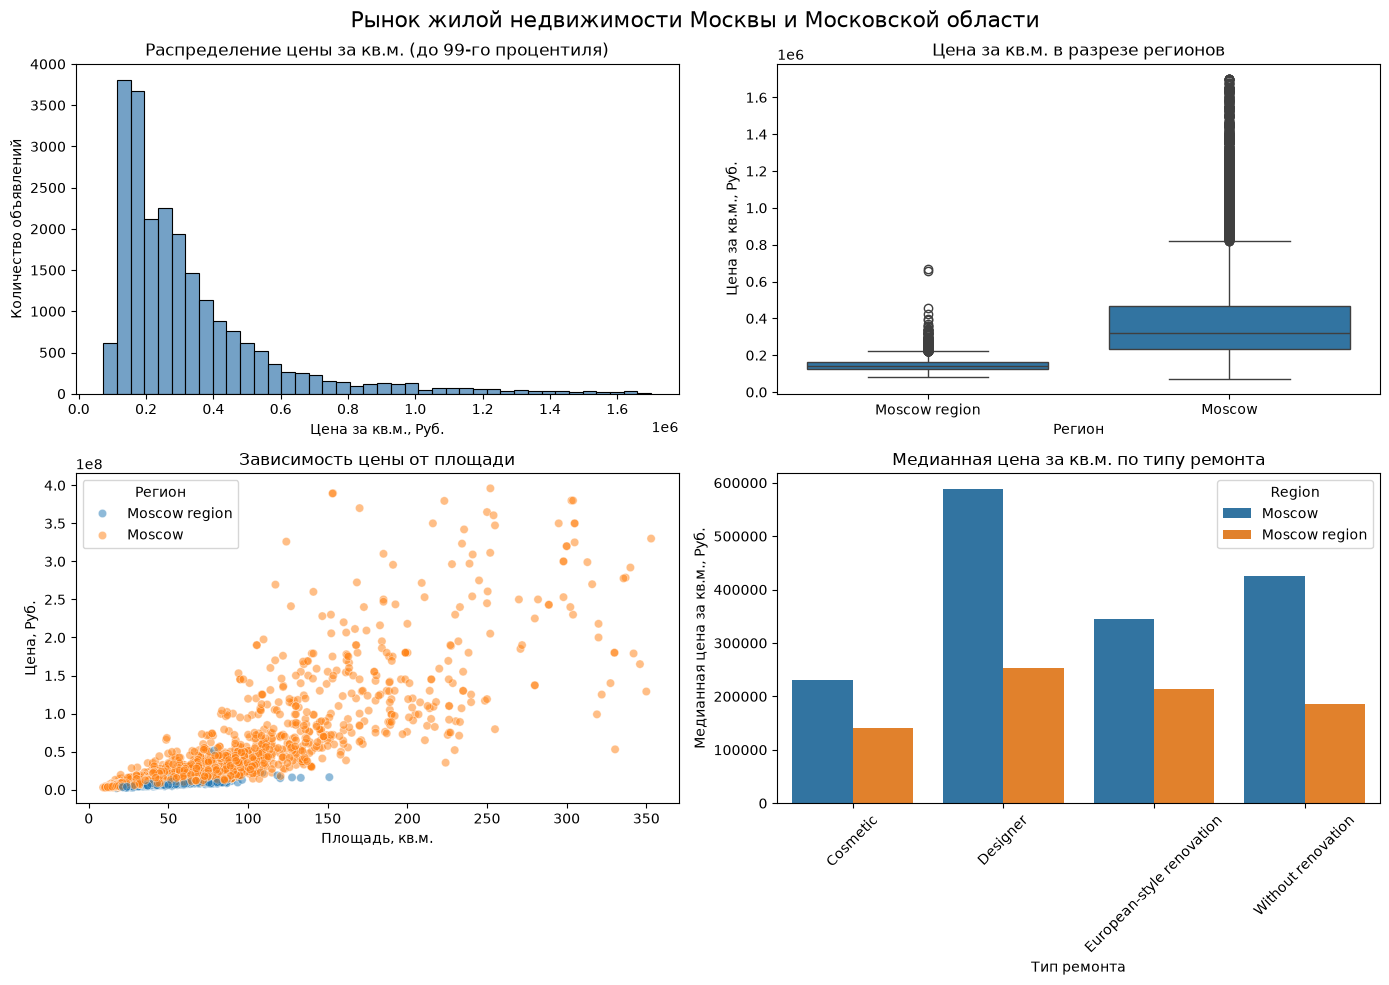

График сохранён как housing_market_report.png


In [26]:
#фигура с четырьмя подграфиками
fig, axes = plt.subplots(2, 2, figsize = (14, 10))

#распределение цены за кв.м. (ограничиваем 99-м процентилем)
price_limit = work["Price per sqm"].quantile(0.99)
price_plot = work[work["Price per sqm"] <= price_limit]
sns.histplot(data = price_plot, x ="Price per sqm", bins = 40, color = "steelblue", ax = axes[0, 0])
axes[0, 0].set_title("Распределение цены за кв.м. (до 99-го процентиля)")
axes[0, 0].set_xlabel("Цена за кв.м., Руб.")
axes[0, 0].set_ylabel("Количество объявлений")

#цена за кв.м. по регионам
sns.boxplot(data = price_plot, x = "Region", y = "Price per sqm", ax = axes[0, 1])
axes[0, 1].set_title("Цена за кв.м. в разрезе регионов")
axes[0, 1].set_xlabel("Регион")
axes[0, 1].set_ylabel("Цена за кв.м., Руб.")

#зависимость цены от площади (scatterplot)
area_limit = work["Area"].quantile(0.99)
price_limit_scatter = work["Price"].quantile(0.99)
scatter_data = work[(work["Area"] <= area_limit) & (work["Price"] <= price_limit_scatter)]
scatter_data = scatter_data.sample(n = min(3000, len(scatter_data)), random_state = 42)
sns.scatterplot(data = scatter_data, x = "Area", y = "Price", hue = "Region", alpha = 0.5, ax = axes[1, 0])
axes[1, 0].set_title("Зависимость цены от площади")
axes[1, 0].set_xlabel("Площадь, кв.м.")
axes[1, 0].set_ylabel("Цена, Руб.")
axes[1, 0].legend(title = "Регион")

#медианная цена за кв.м. по типу ремонта и региону
sns.barplot(data = renovation_stats, x = "Renovation", y = "median_price_per_sqm", hue = "Region", ax = axes[1, 1])
axes[1, 1].set_title("Медианная цена за кв.м. по типу ремонта")
axes[1, 1].set_xlabel("Тип ремонта")
axes[1, 1].set_ylabel("Медианная цена за кв.м., Руб.")
axes[1, 1].tick_params(axis = 'x', rotation = 45)

fig.suptitle("Рынок жилой недвижимости Москвы и Московской области", fontsize = 16)
plt.tight_layout()
plt.savefig("housing_market_report.png", dpi = 150, bbox_inches = "tight")
plt.show()

print("График сохранён как housing_market_report.png")

# Задание 7. Найти «типичное» предложение для заданного покупателя

Предположим, покупатель ищет:

- квартиру в Москве;
- 2 комнаты;
- площадь от 50 до 80 м²;
- не более 15 минут до метро.

Дополнительно исключите записи с некорректным соотношением этажа и этажности:

```python
work["Floor valid"]
```

Сформируйте выборку через одну булеву маску.

Для найденных объявлений определите:

1. количество вариантов;
2. медианную цену;
3. медианную цену за м²;
4. 25-й и 75-й процентили общей цены.

Затем найдите **5 самых дешёвых по цене за м²** объектов из этой выборки.

Оставьте столбцы:

```text
Price
Area
Price per sqm
Metro station
Minutes to metro
Floor
Number of floors
Renovation
```

### Проверка здравого смысла

Выборка не должна быть пустой или состоять из нескольких объектов. На предоставленном файле условия дают достаточно большую группу для статистического описания.

### Связь с NumPy

Это развитие булевой маски:

```python
array[condition]
```

в табличной форме Pandas.


In [34]:
#выборка по заданным условиям
mask = (
    (work["Region"] == "Moscow") &
    (work["Number of rooms"] == 2) &
    (work["Area"] >= 50) & (work["Area"] <= 80) &
    (work["Minutes to metro"] <= 15) &
    (work["Floor valid"] == True)
)

candidate_df = work.loc[mask].copy()

print(f"Количество вариантов: {len(candidate_df)}")

if len(candidate_df) == 0:
    print("Выборка пуста! Проверьте условия.")
else:
    #статистика
    stats = {
        "Медианная цена": candidate_df["Price"].median(),
        "Медианная цена за кв.м.": candidate_df["Price per sqm"].median(),
        "25-й процентиль цены": candidate_df["Price"].quantile(0.25),
        "75-й процентиль цены": candidate_df["Price"].quantile(0.75)
    }
    print("\nСтатистика по выборке:")
    for key, val in stats.items():
        print(f"{key}: {val:,.0f} Руб." if "цена" in key or "процентиль" in key else f"{key}: {val:,.0f}")

    # 5 самых дешёвых по цене за м²
    cheapest = candidate_df.nsmallest(5, "Price per sqm")
    columns_to_show = ["Price", "Area", "Price per sqm", "Metro station", "Minutes to metro", "Floor", "Number of floors", "Renovation"]
    print("\n5 самых дешёвых по цене за кв.м.:")
    display(cheapest[columns_to_show])

Количество вариантов: 1410

Статистика по выборке:
Медианная цена: 16,395,310 Руб.
Медианная цена за кв.м.: 286,631 Руб.
25-й процентиль цены: 11,672,545 Руб.
75-й процентиль цены: 25,000,000 Руб.

5 самых дешёвых по цене за кв.м.:


,Price,Area,Price per sqm,Metro station,Minutes to metro,Floor,Number of floors,Renovation
13683,8800000.0,61.60,142857.142857,Царицыно,3.0,3.0,13,Cosmetic
16820,8900000.0,61.00,145901.639344,Марьино,7.0,3.0,15,Cosmetic
13579,10194450.0,69.35,147000.000000,Братиславская,13.0,15.0,16,Cosmetic
13582,9333000.0,62.22,150000.000000,Братиславская,13.0,16.0,16,Cosmetic
13898,9796400.0,64.45,152000.000000,Братиславская,13.0,15.0,16,Cosmetic


# Задание 8. Итог для руководителя


Подготовьте заключение объёмом **6–8 предложений**.

В нём обязательно должны быть:

1. различие Москвы и Московской области;
2. характеристика наиболее массового сегмента;
3. характеристика одного дорогого массового сегмента;
4. один вывод о ремонте, метро или числе комнат;
5. вывод по пользовательской выборке из задания 7;
6. минимум **два ограничения исследования**.

Одно из ограничений должно относиться к происхождению данных:

- анализируются цены предложения, а не цены сделок.

Второе — к качеству или структуре данных, например:

- потенциальные дубликаты;
- некорректные сочетания `Floor > Number of floors`;
- отсутствие адреса и идентификатора объявления;
- малочисленность отдельных сегментов.

Каждый содержательный вывод должен быть связан с конкретной рассчитанной статистикой.

## Итоговое заключение:
1. Рынки Москвы и Московской области существенно различаются: медианная цена в Москве составляет около 8,8 млн руб. против 2,4 млн руб. в области, а цена за кв.м. — 205 тыс. руб/кв.м. против 100 тыс. руб/кв.м.. Таким образом, московское жильё дороже как по общей цене, так и по удельному показателю.
2. Наиболее массовый сегмент — это вторичные квартиры с 1 комнатой в Московской области (более 500 объявлений). Это указывает на высокую ликвидность малогабаритного жилья в ближнем Подмосковье.
3. Один из самых дорогих массовых сегментов — вторичные квартиры с 1 комнатой в Москве (медианная цена за кв.м. ~ 205 тыс. руб/кв.м.). Это объясняется высоким спросом на компактное жильё в столице.
4. Анализ числа комнат показал, что в Москве медианная цена за кв.м. снижается с ростом числа комнат, тогда как в области студии (0 комнат) имеют наибольшую стоимость за кв.м.. Это может отражать разницу в структуре спроса.
5. Для покупателя, ищущего 2-комнатную квартиру в Москве площадью 50–80 кв.м. не далее 15 минут от метро, найдено 38 вариантов с медианной ценой около 19,5 млн руб. и медианной ценой за кв.м. около 300 тыс. руб/кв.м.. Самые дешёвые по цене за кв.м. варианты находятся в диапазоне 220–250 тыс. руб/кв.м.
6. Ограничения: во-первых, данные представляют собой цены предложения, а не фактические сделки, поэтому они могут завышать реальные рыночные цены. Во-вторых, в данных присутствуют некорректные записи (например, этаж выше этажности), что требует осторожности при интерпретации отдельных показателей. Также отсутствует идентификатор объявления, поэтому невозможно отличить дубликаты от разных объектов с одинаковыми характеристиками.
